# Evidencia 4 — Sintaxis y dependencias

**SONORA · E4-01…04 · corpus completo `lyrics_full_v1`.**

Se reutilizan spaCy 3.8.18 y `en_core_web_sm` 3.8.0, sin NER, ya ejecutados.
No se vuelve a anotar ni se ajusta ningún modelo. Los análisis descriptivos incluyen
todos los splits: no constituyen evaluación predictiva sobre test.
Pipeline: `pipelines/nlp/e4_syntax.py`; módulo: `sonora.nlp.syntax`.

Las métricas cubren las **3 155 772 letras**, los diez shards y las 6 317 partes
de oraciones. Los árboles y la auditoría estructural detallada usan una selección
declarada; no sustituyen los agregados del corpus completo.

## 1. Convenciones y denominadores (E4-03)

- Unidad: segmento que devuelve el parser con frontera forzada por salto de verso.
  Un verso puede subdividirse y una oración gramatical puede continuar en otro verso.
  Por eso llamamos a la unidad **segmento anotado**, no oración gramatical certificada.
- Longitud: `n_words` cuenta tokens sin espacio y sin `is_punct`; conserva números,
  símbolos y clíticos. Es una política distinta de excluir UPOS PUNCT/SYM/SPACE en E3.
- Profundidad: máximo número de saltos hasta la raíz de los tokens no puntuación;
  raíz = 0. Los caminos siguen el árbol original, sin comprimir nodos intermedios.
- Distancia: \(d=|tok_i-head_i|\), con índices originales de spaCy. Se excluyen
  la raíz y arcos cuyo dependiente **o cabeza** sea puntuación. Los espacios/puntuación
  entre extremos siguen aportando posiciones; no se renumera el texto.
- Media global por arco: \(\sum_s n_s\bar d_s/\sum_s n_s\).
  La media por segmento con arcos, \(\sum_s\bar d_s/|S_{arcos}|\), se muestra por separado.
  No confundir ponderación por arcos con media de medias.
- Las medias de distancias de entrada están en float32; la agregación usa float64.
  La media ponderada reconstruida tiene el pequeño redondeo de las medias originales.
- Segmentos sin arcos: distancia no definida, nunca cero. Se incluyen en los
  denominadores de longitud/profundidad y se contabilizan explícitamente.
  Raíz no verbal y profundidad cero no se consideran errores automáticamente.
- Décadas: sólo `year` entre 1900 y 2022; demás años desconocidos. Los tags y años
  son metadatos de la fuente, no géneros o fechas de composición validados.

Se validaron valores finitos, conteos no negativos y coherencia entre distancia nula
y ausencia de arcos en **cada lote**. Una anomalía numérica detiene la ejecución;
no se excluyen silenciosamente filas. Esto no verifica la corrección lingüística del parser.

In [1]:
import json,sys
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'packages/sonora/src'))
from sonora import viz
from sonora.nlp.syntax import FIELDS, normalized, draw_tree
viz.apply_style()
FIG=ROOT/'reports/figures/E4'
summary=json.loads((ROOT/'reports/nlp/lyrics_full_v1/e4_summary.json').read_text(encoding='utf-8'))
audit=json.loads((ROOT/'reports/nlp/lyrics_full_v1/e4_examples.json').read_text(encoding='utf-8'))
g=summary['global_metrics']
assert summary['docs']==3155772 and summary['parts']==6317
assert g['tokens']==1033733693 and g['sentences']==144457653
def show(rows):
    if not rows: return
    cols=list(rows[0])
    def fmt(v):
        if v is None: return '—'
        if isinstance(v,float): return f'{v:.4f}'
        return str(v).replace('|',r'\|').replace('\n',' / ')
    display(Markdown('\n'.join(['| '+' | '.join(cols)+' |','|'+'---|'*len(cols)]+
                    ['| '+' | '.join(fmt(r[k]) for k in cols)+' |' for r in rows])))
def combine(rows):
    return normalized([sum(r[k] for r in rows) for k in FIELDS])
def quantile_hist(hist,q):
    pairs=sorted((int(k),v) for k,v in hist.items()); target=max(1,int(np.ceil(q*sum(v for k,v in pairs))))
    total=0
    for k,v in pairs:
        total+=v
        if total>=target:return k
print('Configuración:',summary['annotation_config'])
show([{'medida':k,'valor':v} for k,v in {'letras':summary['docs'],'partes':summary['parts'],**g}.items()])
show([{'variable':k,**{f'p{int(q*100)}':quantile_hist(h,q) for q in [.5,.9,.95,.99,1]}}
      for k,h in summary['hist'].items()])

Configuración: {'annotation_version': 'spacy-lines-gdrop-v1', 'model': 'en_core_web_sm', 'model_version': '3.8.0', 'spacy': '3.8.18', 'sentence_policy': 'line_break_forced_boundary_plus_parser', 'text_view': 'lyrics_analysis', 'docs_per_task': 500, 'corpus_run_id': 'lyrics_full_v1', 'gdrop_forms_sha256': '8d9d55bd487582412f1f29136590fee06d10ebc0915acfea0991c1212864da1e'}


| medida | valor |
|---|---|
| letras | 3155772 |
| partes | 6317 |
| sentences | 144457653 |
| tokens | 1033733693 |
| words | 953078393 |
| depth_sum | 352665192.0000 |
| arcs | 809010838 |
| distance_sum | 1566244066.5844 |
| sentence_distance_sum | 236684401.1796 |
| sentences_with_arcs | 133427079 |
| no_arcs | 11030574 |
| no_words | 1186993 |
| zero_depth | 10901195 |
| nonverbal_roots | 40981827 |
| mean_words | 6.5976 |
| mean_depth | 2.4413 |
| mean_dependency_distance | 1.9360 |
| mean_sentence_dependency_distance | 1.7739 |

| variable | p50 | p90 | p95 | p99 | p100 |
|---|---|---|---|---|---|
| n_words | 6 | 11 | 13 | 17 | 1493 |
| depth | 2 | 4 | 5 | 6 | 180 |

## 2. Distribuciones del corpus completo

Percentiles por rango más próximo, ponderados por número de segmentos, no por letra.
Las figuras se recortan al p99 únicamente para legibilidad: las tablas incluyen el máximo
y los promedios conservan toda la cola. No se elimina ni winsoriza ninguna observación.

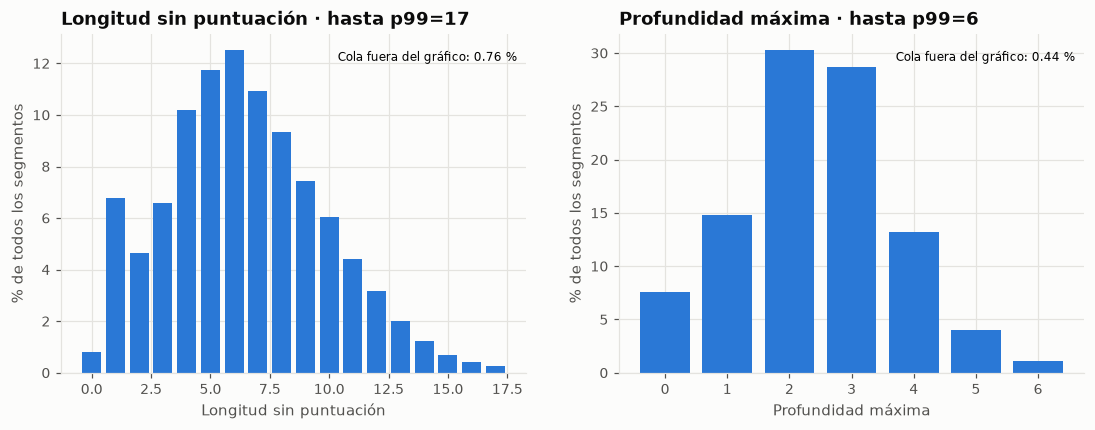

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,key,label in zip(axes,['n_words','depth'],['Longitud sin puntuación','Profundidad máxima']):
    h=summary['hist'][key]; limit=quantile_hist(h,.99)
    pairs=sorted((int(k),v) for k,v in h.items() if int(k)<=limit)
    ax.bar([k for k,v in pairs],[100*v/g['sentences'] for k,v in pairs],color=viz.SEQUENTIAL)
    tail=sum(v for k,v in h.items() if int(k)>limit)
    ax.set(xlabel=label,ylabel='% de todos los segmentos',title=f'{label} · hasta p99={limit}')
    ax.text(.98,.95,f'Cola fuera del gráfico: {100*tail/g["sentences"]:.2f} %',
            transform=ax.transAxes,ha='right',va='top',fontsize=8)
viz.save(fig,FIG/'distribuciones.png');plt.show()

## 3. Comparación por tag, década y longitud (E4-03/04)

Las medias de longitud y profundidad ponderan segmentos; la distancia pondera arcos.
Se muestran letras, segmentos y arcos para conocer el soporte. La agregación global
no es una media simple de cinco tags. Comparar bandas de longitud reduce un factor
de confusión, pero las bandas siguen conteniendo longitudes y composiciones diferentes.

| tag | docs | sentences | arcs | mean_words | mean_depth | mean_dependency_distance | no_arcs | nonverbal_roots |
|---|---|---|---|---|---|---|---|---|
| pop | 1336051 | 51479539 | 266782942 | 6.1786 | 2.3315 | 1.8796 | 3536262 | 14397681 |
| rap | 959763 | 60710312 | 373599526 | 7.1527 | 2.5742 | 2.0060 | 5370940 | 17587777 |
| rock | 621148 | 21471696 | 109603654 | 6.1006 | 2.3677 | 1.8390 | 1250282 | 6069727 |
| rb | 153552 | 7923838 | 41392332 | 6.2188 | 2.2657 | 1.9314 | 738947 | 2231946 |
| country | 85258 | 2872268 | 17632384 | 7.1368 | 2.6342 | 1.9205 | 134143 | 694696 |

| década | docs | sentences | arcs | mean_words | mean_depth | mean_dependency_distance | no_arcs | nonverbal_roots |
|---|---|---|---|---|---|---|---|---|
| 1900 | 100 | 2886 | 15701 | 6.4449 | 2.5135 | 1.9485 | 156 | 982 |
| 1910 | 182 | 6458 | 45161 | 7.9704 | 2.7964 | 2.1370 | 480 | 1974 |
| 1920 | 1361 | 36996 | 240025 | 7.4886 | 2.6736 | 2.0355 | 1682 | 8936 |
| 1930 | 1096 | 30363 | 178016 | 6.8597 | 2.5225 | 2.0036 | 1731 | 8500 |
| 1940 | 1200 | 35271 | 199703 | 6.6583 | 2.4830 | 1.9515 | 1929 | 10137 |
| 1950 | 9014 | 241732 | 1357130 | 6.6115 | 2.4661 | 1.9269 | 11761 | 67725 |
| 1960 | 39341 | 1158109 | 6432566 | 6.5506 | 2.4284 | 1.9349 | 68797 | 320345 |
| 1970 | 62259 | 2169776 | 11779812 | 6.4244 | 2.4241 | 1.9170 | 133390 | 605062 |
| 1980 | 93673 | 3691798 | 18978395 | 6.1347 | 2.3635 | 1.8718 | 235168 | 1069760 |
| 1990 | 213283 | 8455685 | 45584848 | 6.3854 | 2.4373 | 1.9003 | 566560 | 2509684 |
| 2000 | 435534 | 17360158 | 96061004 | 6.5292 | 2.4674 | 1.9067 | 1115310 | 4928338 |
| 2010 | 1582505 | 75475785 | 427697347 | 6.6641 | 2.4552 | 1.9425 | 5874208 | 21387719 |
| 2020 | 714159 | 35690847 | 199735814 | 6.5953 | 2.4087 | 1.9501 | 3009379 | 10031214 |
| — | 2065 | 101789 | 705316 | 7.9245 | 2.5882 | 2.3165 | 10023 | 31451 |

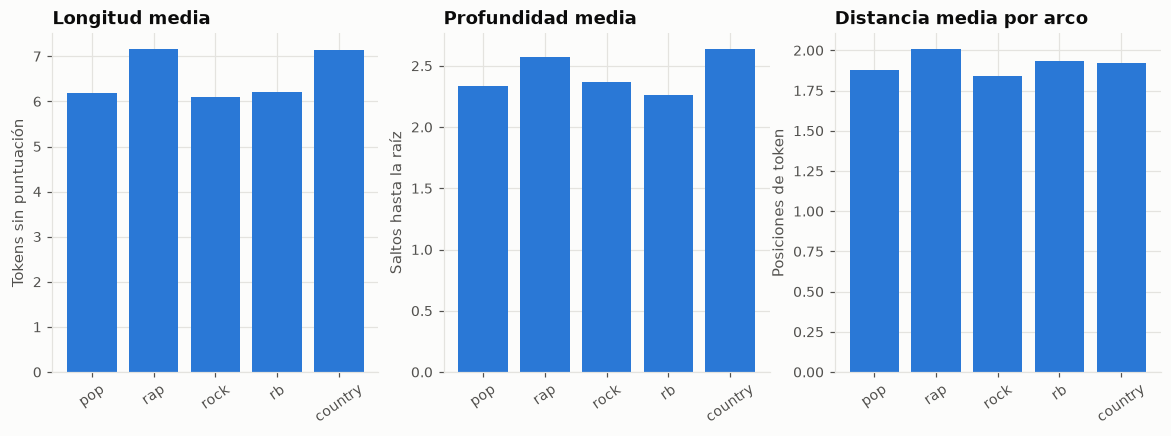

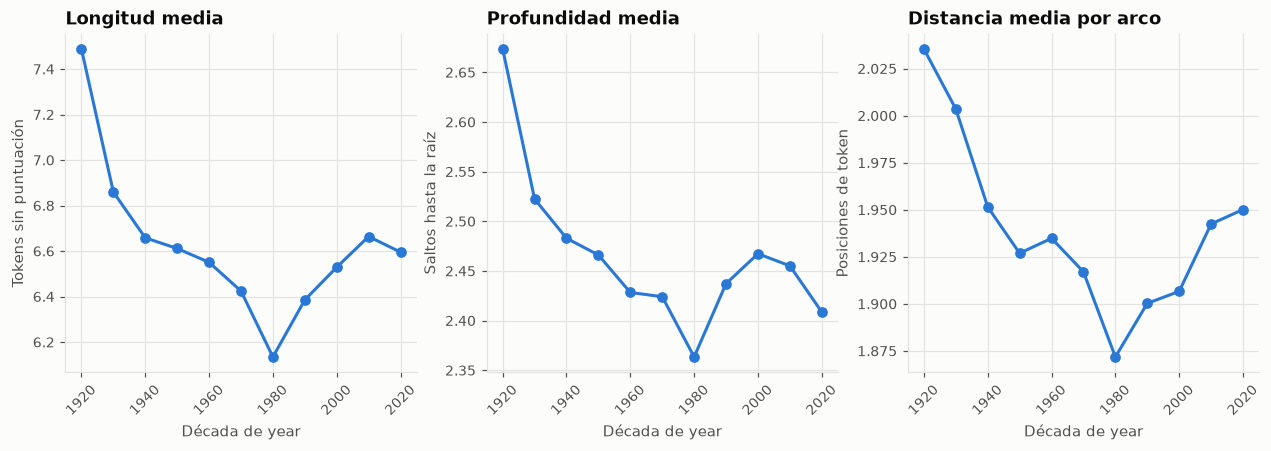

| tag | band | segmentos | arcos | mean_words | mean_depth | mean_dependency_distance |
|---|---|---|---|---|---|---|
| pop | 0–4 | 15833594 | 28099528 | 2.7517 | 1.1761 | 1.4601 |
| pop | 5–9 | 28553885 | 161945046 | 6.6760 | 2.6148 | 1.8044 |
| pop | 10–19 | 6973658 | 73472596 | 11.5422 | 3.7321 | 2.1517 |
| pop | 20+ | 118402 | 3265772 | 28.5966 | 6.0217 | 3.0954 |
| rap | 0–4 | 16242926 | 23991829 | 2.4514 | 1.0130 | 1.4421 |
| rap | 5–9 | 28719044 | 170108263 | 6.9305 | 2.7465 | 1.8348 |
| rap | 10–19 | 15274556 | 165585785 | 11.8492 | 3.8034 | 2.1722 |
| rap | 20+ | 473786 | 13913649 | 30.3835 | 6.0290 | 3.0937 |
| rock | 0–4 | 6770607 | 12673183 | 2.8515 | 1.2650 | 1.4430 |
| rock | 5–9 | 11976110 | 67483477 | 6.6381 | 2.6557 | 1.7781 |
| rock | 10–19 | 2676571 | 28180998 | 11.5335 | 3.8003 | 2.1149 |
| rock | 20+ | 48408 | 1265996 | 27.1666 | 6.1372 | 2.9144 |
| rb | 0–4 | 2532784 | 3987130 | 2.5434 | 1.0396 | 1.4774 |
| rb | 5–9 | 4142153 | 23683068 | 6.7240 | 2.5779 | 1.8315 |
| rb | 10–19 | 1224399 | 13054295 | 11.6711 | 3.6774 | 2.1948 |
| rb | 20+ | 24502 | 667839 | 28.2746 | 5.6987 | 3.0372 |
| country | 0–4 | 567299 | 1021685 | 2.7755 | 1.1787 | 1.4800 |
| country | 5–9 | 1689049 | 9942981 | 6.8902 | 2.6884 | 1.8178 |
| country | 10–19 | 607815 | 6459328 | 11.6314 | 3.7958 | 2.1184 |
| country | 20+ | 8105 | 208390 | 26.7287 | 6.0941 | 2.8473 |

| tag | década | letras | segmentos | mean_words | mean_depth | mean_dependency_distance |
|---|---|---|---|---|---|---|
| country | 1970 | 6763 | 174405 | 7.7381 | 2.8035 | 1.9407 |
| country | 2020 | 14189 | 546844 | 7.0323 | 2.5986 | 1.9322 |
| pop | 1970 | 32461 | 1103360 | 6.3542 | 2.4086 | 1.8947 |
| pop | 2020 | 234475 | 10272637 | 6.1301 | 2.2778 | 1.8957 |
| rap | 1970 | 216 | 17008 | 7.5841 | 2.7815 | 2.0795 |
| rap | 2020 | 306458 | 18409404 | 7.0286 | 2.5148 | 2.0025 |
| rb | 1970 | 6176 | 293272 | 6.0843 | 2.2627 | 1.9911 |
| rb | 2020 | 48134 | 2453415 | 6.1520 | 2.2415 | 1.9179 |
| rock | 1970 | 16643 | 581731 | 6.3014 | 2.4109 | 1.9090 |
| rock | 2020 | 110903 | 4008547 | 6.0091 | 2.3335 | 1.8267 |

In [3]:
groups=summary['groups']; tags=viz.TAG_ORDER
by_tag=[dict(tag=t,docs=sum(r['docs'] for r in groups if r['tag']==t),
             **combine([r for r in groups if r['tag']==t])) for t in tags]
decades=sorted({r['decade'] for r in groups if r['decade'] is not None})
by_dec=[dict(decade=d,docs=sum(r['docs'] for r in groups if r['decade']==d),
             **combine([r for r in groups if r['decade']==d])) for d in decades+[None]]
metrics=['mean_words','mean_depth','mean_dependency_distance']
cols=['docs','sentences','arcs']+metrics+['no_arcs','nonverbal_roots']
show([{'tag':r['tag'],**{k:r[k] for k in cols}} for r in by_tag])
show([{'década':r['decade'],**{k:r[k] for k in cols}} for r in by_dec])
assert sum(r['sentences'] for r in by_tag)==g['sentences']==sum(r['sentences'] for r in by_dec)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,key,title,unit in zip(axes,metrics,['Longitud media','Profundidad media','Distancia media por arco'],
                           ['Tokens sin puntuación','Saltos hasta la raíz','Posiciones de token']):
    ax.bar([r['tag'] for r in by_tag],[r[key] for r in by_tag],color=viz.SEQUENTIAL)
    ax.set(title=title,ylabel=unit)
    ax.tick_params(axis='x',rotation=35)
viz.save(fig,FIG/'comparacion_tags.png');plt.show()
visible=[r for r in by_dec if r['decade'] is not None and r['docs']>=1000]
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,key,title,unit in zip(axes,metrics,['Longitud media','Profundidad media','Distancia media por arco'],
                           ['Tokens sin puntuación','Saltos hasta la raíz','Posiciones de token']):
    ax.plot([r['decade'] for r in visible],[r[key] for r in visible],marker='o')
    ax.set(title=title,xlabel='Década de year',ylabel=unit);ax.tick_params(axis='x',rotation=45)
viz.save(fig,FIG/'comparacion_decadas.png');plt.show()
show([{'tag':r['tag'],'band':r['band'],'segmentos':r['sentences'],'arcos':r['arcs'],
       **{k:r[k] for k in metrics}} for r in summary['by_length']])
show([{'tag':r['tag'],'década':r['decade'],'letras':r['docs'],'segmentos':r['sentences'],
       **{k:r[k] for k in metrics}} for r in groups if r['decade'] in [1970,2020]])

## 4. Auditoría de grafos y árboles dirigidos (E4-01/02/04)

Selección dirigida: primera parte de tokens de cada shard (hasta 500 letras por parte).
Se auditan todos sus segmentos buscando raíz única, coherencia de ROOT, cabezas presentes
y ciclos. Son comprobaciones estructurales de los archivos exportados; un árbol puede
superarlas y ser lingüísticamente erróneo. Una cabeza ausente puede deberse a la exportación
sin espacios, por lo que no se adjudica automáticamente el fallo al parser original.

Se eligen cuatro árboles cortos (3–10 tokens): construcción con `nsubj` y `dobj`, cláusula
subordinada (`advcl/ccomp/relcl`), coordinación (`cc/conj`) y segmento sin VERB/AUX.
Se priorizan tags distintos y se exigen letras diferentes; se conserva el primer candidato
por criterio/tag en orden de archivo. Son casos ilustrativos, no prevalencias del corpus.
La etiqueta del criterio depende de predicciones del parser, por eso se revisa su lectura.

Los árboles usan **flechas cabeza → dependiente**, índices originales debajo del POS y
etiquetas de dependencia de spaCy (incluyen `dobj`; no se renombran como UD v2).
No son árboles de constituyentes. `nsubj/dobj` describen relaciones sintácticas:
no certifican papeles semánticos agente/paciente ni sentimiento.

Auditoría dirigida: 5000 letras; 244951 segmentos
Anomalías estructurales por tipo (pueden solaparse): {}
Partes:
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00000-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00001-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00002-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00003-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00004-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00005-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00006-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00007-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00008-of-00010/part-00000.parquet
data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tok

### transitive · country

`lyr_79bf500aa6f551ad02e4` · `sent_i=0` · `line_i=0`

Archivo: `data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00000-of-00010/part-00000.parquet`

Métricas del árbol: {'issues': [], 'roots': [2], 'depth': 2, 'n_arcs': 8, 'mean_dep_dist': 2.625}


| tok_i | dependiente | POS | lema | relación | head_i | cabeza |
|---|---|---|---|---|---|---|
| 0 | We | PRON | we | nsubj | 2 | leave |
| 1 | could | AUX | could | aux | 2 | leave |
| 2 | leave | VERB | leave | ROOT | 2 | leave |
| 3 | the | DET | the | det | 5 | lights |
| 4 | Christmas | PROPN | Christmas | compound | 5 | lights |
| 5 | lights | NOUN | light | dobj | 2 | leave |
| 6 | up | ADP | up | prt | 2 | leave |
| 7 | ' | PROPN | ' | punct | 2 | leave |
| 8 | til | PROPN | til | compound | 9 | January |
| 9 | January | PROPN | January | npadvmod | 2 | leave |

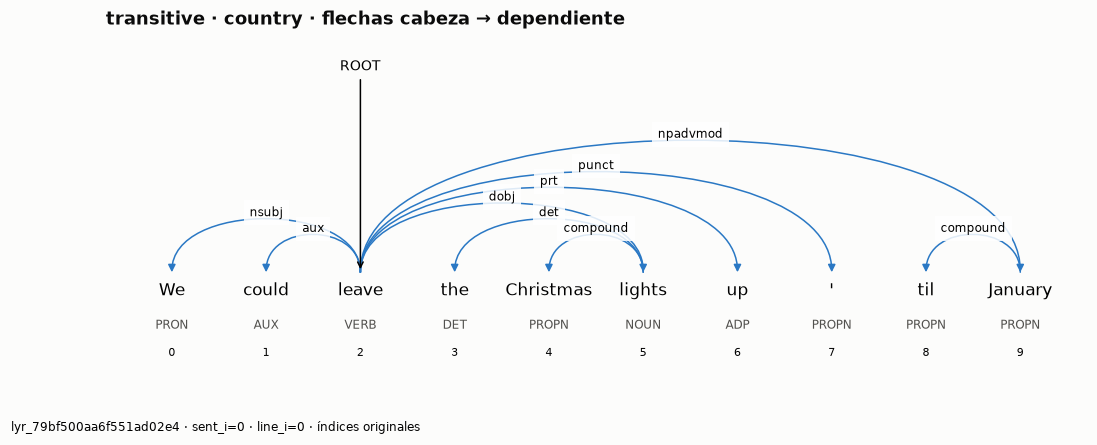

### subordinate · pop

`lyr_2315a48e066ced8009d6` · `sent_i=1` · `line_i=1`

Archivo: `data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00000-of-00010/part-00000.parquet`

Métricas del árbol: {'issues': [], 'roots': [15], 'depth': 2, 'n_arcs': 6, 'mean_dep_dist': 1.8333333333333333}


| tok_i | dependiente | POS | lema | relación | head_i | cabeza |
|---|---|---|---|---|---|---|
| 12 | So | ADV | so | advmod | 15 | is |
| 13 | the | DET | the | det | 14 | bar |
| 14 | bar | NOUN | bar | nsubj | 15 | is |
| 15 | is | AUX | be | ROOT | 15 | is |
| 16 | where | SCONJ | where | advmod | 18 | go |
| 17 | I | PRON | I | nsubj | 18 | go |
| 18 | go | VERB | go | advcl | 15 | is |

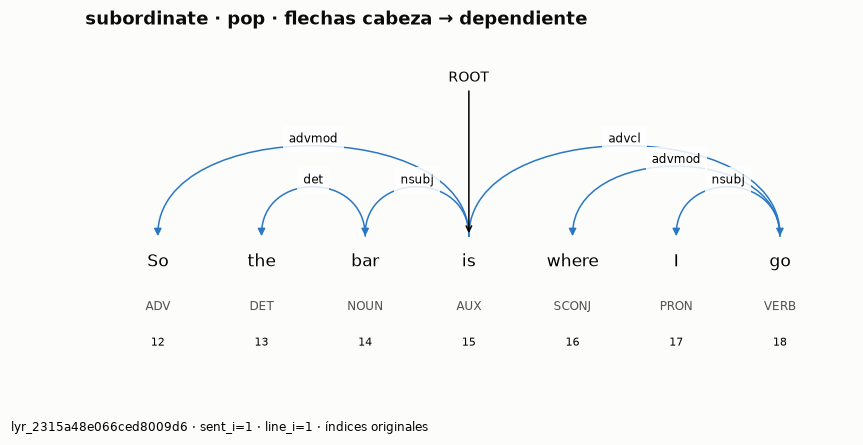

### coordination · rap

`lyr_94b5237c6f7464b6c4b5` · `sent_i=17` · `line_i=17`

Archivo: `data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00000-of-00010/part-00000.parquet`

Métricas del árbol: {'issues': [], 'roots': [234], 'depth': 3, 'n_arcs': 7, 'mean_dep_dist': 2.0}


| tok_i | dependiente | POS | lema | relación | head_i | cabeza |
|---|---|---|---|---|---|---|
| 234 | Made | VERB | make | ROOT | 234 | Made |
| 235 | a | DET | a | det | 236 | livin' |
| 236 | livin' | NOUN | living | dobj | 234 | Made |
| 237 | and | CCONJ | and | cc | 234 | Made |
| 238 | a | DET | a | det | 239 | killin' |
| 239 | killin' | NOUN | killing | conj | 234 | Made |
| 240 | off | ADP | off | prt | 239 | killin' |
| 241 | it | PRON | it | pobj | 240 | off |

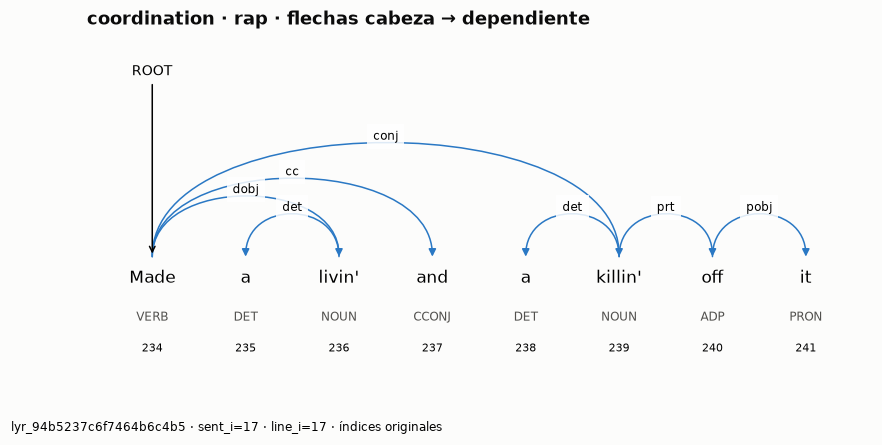

### fragment · rb

`lyr_9b869033ae33f65fdae4` · `sent_i=56` · `line_i=61`

Archivo: `data/processed/nlp/lyrics_full_v1/spacy_sm_v1/tokens/train-00000-of-00010/part-00000.parquet`

Métricas del árbol: {'issues': [], 'roots': [589], 'depth': 1, 'n_arcs': 2, 'mean_dep_dist': 1.5}


| tok_i | dependiente | POS | lema | relación | head_i | cabeza |
|---|---|---|---|---|---|---|
| 588 | Yene | PROPN | Yene | compound | 589 | konjo |
| 589 | konjo | NOUN | konjo | ROOT | 589 | konjo |
| 590 | , | PUNCT | , | punct | 589 | konjo |
| 591 | ewedihalehu | PROPN | ewedihalehu | appos | 589 | konjo |

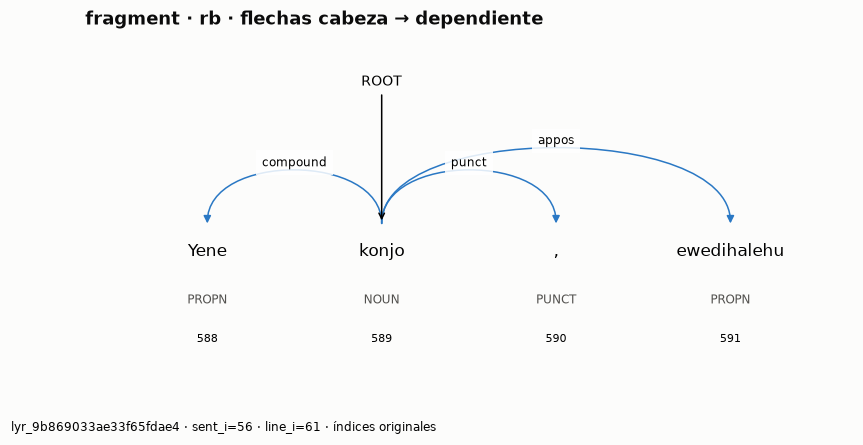

In [4]:
print('Auditoría dirigida:',audit['sample_docs'],'letras;',audit['sample_segments'],'segmentos')
print('Anomalías estructurales por tipo (pueden solaparse):',audit['graph_issues'])
print('Partes:',*audit['files'],sep='\n')
assert len(audit['examples'])>=3 and len({e['lyrics_id'] for e in audit['examples']})==len(audit['examples'])
for e in audit['examples']:
    display(Markdown(f"### {e['criterion']} · {e['tag']}\n\n`{e['lyrics_id']}` · "
                     f"`sent_i={e['sent_i']}` · `line_i={e['line_i']}`\n\nArchivo: `{e['file']}`"))
    print('Métricas del árbol:',e['audit'])
    index={r['tok_i']:r for r in e['tokens']}
    show([{'tok_i':r['tok_i'],'dependiente':r['text'],'POS':r['upos'],'lema':r['lemma'],
           'relación':r['dep'],'head_i':r['head_i'],'cabeza':index[r['head_i']]['text']}
           for r in e['tokens']])
    fig=draw_tree(e,FIG/f"arbol_{e['criterion']}.png");plt.show()

## 5. Hallazgos calculados y límites

In [5]:
lo=min(by_tag,key=lambda r:r['mean_words']);hi=max(by_tag,key=lambda r:r['mean_words'])
display(Markdown(f"""
- El corpus completo contiene **{g['sentences']:,} segmentos anotados**, con
  longitud media **{g['mean_words']:.4f}**, profundidad media **{g['mean_depth']:.4f}**
  y distancia media por arco **{g['mean_dependency_distance']:.4f}** posiciones.
  La media de distancias por segmento con arcos es **{g['mean_sentence_dependency_distance']:.4f}**;
  la diferencia se debe a la ponderación, no a otro parser.
- **{g['no_arcs']:,} segmentos** no tienen arcos incluidos
  ({100*g['no_arcs']/g['sentences']:.3f} %). Su distancia no está definida;
  no se sustituyó por cero para disminuir artificialmente la media.
- **{g['nonverbal_roots']:,} segmentos** tienen raíz con POS distinto de VERB/AUX
  ({100*g['nonverbal_roots']/g['sentences']:.3f} %). Esto permite describir salidas nominales
  o fragmentarias, pero no contar oraciones incorrectas.
- La mayor longitud media por tag es **{hi['tag']} ({hi['mean_words']:.4f})** y la menor
  **{lo['tag']} ({lo['mean_words']:.4f})**. Profundidad y distancia dependen en parte de
  longitud; las tablas por bandas y dentro de tag/década evitan atribuir directamente
  la diferencia al género. Tampoco prueban mayor complejidad artística o calidad lingüística.
- Los gráficos temporales usan grupos con al menos 1 000 letras; sus tablas conservan
  todos los grupos y años desconocidos. Cambios de composición por artista/tag y la
  fragmentación por verso impiden interpretar las curvas como evolución causal.
"""))


- El corpus completo contiene **144,457,653 segmentos anotados**, con
  longitud media **6.5976**, profundidad media **2.4413**
  y distancia media por arco **1.9360** posiciones.
  La media de distancias por segmento con arcos es **1.7739**;
  la diferencia se debe a la ponderación, no a otro parser.
- **11,030,574 segmentos** no tienen arcos incluidos
  (7.636 %). Su distancia no está definida;
  no se sustituyó por cero para disminuir artificialmente la media.
- **40,981,827 segmentos** tienen raíz con POS distinto de VERB/AUX
  (28.369 %). Esto permite describir salidas nominales
  o fragmentarias, pero no contar oraciones incorrectas.
- La mayor longitud media por tag es **rap (7.1527)** y la menor
  **rock (6.1006)**. Profundidad y distancia dependen en parte de
  longitud; las tablas por bandas y dentro de tag/década evitan atribuir directamente
  la diferencia al género. Tampoco prueban mayor complejidad artística o calidad lingüística.
- Los gráficos temporales usan grupos con al menos 1 000 letras; sus tablas conservan
  todos los grupos y años desconocidos. Cambios de composición por artista/tag y la
  fragmentación por verso impiden interpretar las curvas como evolución causal.


## 6. Revisión lingüística y cierre de E4

**Fecha: 2026-11-16. Estado: cierre técnico y documental completado; revisión asistida
realizada. La lectura y validación personal del autor siguen pendientes y no se presumen.**

Los pendientes humanos se centralizan en [`TODO-human.md`](../TODO-human.md), H03–H06.

### Hallazgos contrastados con los datos

- Las 3 155 772 letras contienen **144 457 653 segmentos anotados** y
  **809 010 838 arcos incluidos**. Longitud media: 6,5976 tokens sin puntuación;
  profundidad media: 2,4413 saltos; distancia media por arco: 1,9360 posiciones.
  La media de distancias por segmento con arcos es 1,7739: usarla como si ponderara
  arcos produciría otro estimando. La longitud incluye clíticos, números y símbolos.
- Hay **11 030 574 segmentos sin arcos**, **1 186 993 sin tokens no puntuación**
  y **40 981 827 con raíz no VERB/AUX**. Son categorías diferentes y pueden solaparse.
  Ninguna equivale automáticamente a una oración mal analizada; una raíz nominal puede
  ser compatible con una expresión breve, y una frontera por verso puede partir una oración.
- `rap` presenta longitud media 7,1527 y distancia 2,0060; `rock`, 6,1006 y 1,8390.
  Sin embargo, `country` alcanza profundidad 2,6342 frente a 2,5742 de `rap`.
  Las métricas no ordenan los tags de una única manera ni definen complejidad artística.
- Parte de las diferencias depende de longitud. En la banda 5–9 tokens, la profundidad
  de `rap` es 2,7465 y la de `country` 2,6884: el orden cambia respecto de la media
  global de esos tags. La distancia en esa banda es 1,8348 y 1,8178, respectivamente.
  Las bandas reducen un factor de confusión, pero no controlan exactamente la longitud
  ni artista, estilo o calidad del parser.
- Entre 1970 y 2020, la longitud global pasa de 6,4244 a 6,5953, mientras en `pop`
  baja de 6,3542 a 6,1301 y en `country` de 7,7381 a 7,0323. La mezcla del dataset
  puede producir una evolución agregada distinta de la observada dentro de los tags.
  No se atribuye el contraste a un cambio causal del lenguaje. `rap` de 1970 sólo
  tiene 216 letras, frente a 306 458 de la década 2020, y exige particular cautela.

Los hallazgos anteriores se obtienen de `e4_summary.json`. Los diez shards se procesaron
en un solo proceso, por lotes, con checkpoints por shard. El tiempo de agregación se
registra en su campo `seconds`; no incluye auditoría dirigida ni generación del notebook.
Los datos originales y la anotación spaCy permanecen intactos.

### Lectura de los cuatro árboles (E4-01/02/04)

Cada árbol incluye tabla de tokens, cabeza, etiqueta, POS, lema, archivo y posiciones
originales. Sus profundidades, números de arcos y distancias se recalcularon desde los
tokens y coinciden con las partes de oraciones originales (tolerancia float32 de 1e-6).
La revisión lingüística propone lecturas; no modifica las predicciones ni constituye gold.

| Criterio y localizador | Lectura y limitación |
|---|---|
| Transitiva · `country` · `lyr_79bf500aa6f551ad02e4`, sent_i 0, line_i 0 | Raíz `leave`; `We`→`leave` (`nsubj`) y `lights`→`leave` (`dobj`) son relaciones plausibles; `could` aporta auxiliar/modalidad. Sujeto/objeto son funciones sintácticas, no etiquetas universales de agente/paciente. El final temporal recibe un análisis dudoso: `til` como PROPN y compuesto de `January`; requiere revisión contextual. La validez estructural no elimina ese problema. |
| Subordinada · `pop` · `lyr_2315a48e066ced8009d6`, sent_i 1, line_i 1 | `bar` depende de `is` como `nsubj`; `I` depende de `go` como `nsubj`; `go` se une a `is` con `advcl`. La secuencia con `where` introduce contenido locativo y funciona en la predicación copulativa: llamar a todo ello un adjunto adverbial sin discusión sería simplificar. La selección se basa en la etiqueta `advcl` del parser, no en una clasificación humana ya confirmada. |
| Coordinación · `rap` · `lyr_94b5237c6f7464b6c4b5`, sent_i 17, line_i 17 | `livin'` y `killin'` están etiquetados NOUN y la lectura favorece coordinación nominal. Sin embargo, `killin'` se adjunta mediante `conj` a `Made`, no a `livin'`; `and` también se une al verbo. Hay un probable error de alcance de coordinación. `off` marcado `prt` bajo un nombre merece revisión. El sujeto omitido no se inventa como token. |
| Fragmento sin VERB/AUX · `rb` · `lyr_9b869033ae33f65fdae4`, sent_i 56, line_i 61 | El parser produce raíz nominal `konjo`, con `Yene` como `compound` y `ewedihalehu` como `appos`. Las formas y versos vecinos no permiten una interpretación inglesa segura. Se conserva el caso y se señala para auditoría de idioma/contexto; no se asigna un idioma ni se valida la sintaxis sin evidencia. Una letra predominantemente inglesa puede contener un pasaje en otra lengua. “Sin VERB/AUX predicho” no demuestra fragmentación gramatical correcta. |

Los cuatro árboles son de **cuatro letras y cuatro tags**, pero todos proceden de la
primera parte del shard 0 porque el criterio conserva el primer hallazgo. No son
representativos de cada tag. La auditoría de grafos sí cubrió las primeras partes de
los diez shards: **5 000 letras, 244 951 segmentos**, sin anomalías en las comprobaciones
de raíz, etiqueta ROOT, cabezas presentes y ciclos. Ese resultado sólo concierne a esa
selección y a esas propiedades estructurales, **no a precisión lingüística** ni al estado
de todos los árboles del corpus.

El ejemplo de E3 sin verbo y su continuación entre versos refuerza el límite de segmentación.
No se presenta la profundidad de segmentos forzados como profundidad de oraciones completas.
No se ejecutó un parser de constituyentes ni se presenta un chunker como tal.

### Cobertura y reproducibilidad

| Requisito | Evidencia | Estado |
|---|---|---|
| E4-01 árboles y parser | Cuatro árboles con criterios, procedencia e índices; versiones y convenciones documentadas | Implementado y ejecutado; lectura personal pendiente |
| E4-02 relaciones | Tablas cabeza–dependiente, etiquetas y comentario individual, con separación sintaxis/semántica | Revisión asistida realizada; confirmar juicios |
| E4-03 complejidad | Longitud, profundidad y dos ponderaciones de distancia, distribuciones, denominadores y exclusiones sobre todo el corpus | Reconciliado y ejecutado |
| E4-04 comparación y límites | Tags, décadas, bandas de longitud, contraste temporal dentro de tag; fragmentos y parses dudosos discutidos | Ejecutado; revisión personal pendiente |

Desde `B:\SONORA`, con la `.venv` activa:

```powershell
python pipelines/nlp/e4_syntax.py
python notebooks/evidencias/build_e4.py
```

El pipeline lee `spacy_sm_v1/sentences/`, `doc_stats/` y partes seleccionadas de
`tokens/`; no ejecuta spaCy. Los checkpoints quedan en
`data/processed/nlp/lyrics_full_v1/syntax/e4-syntax-v2/` y sólo se reutilizan si coinciden configuración,
código y firmas de entradas. Se usa lock de un único escritor; no borrar salidas para
forzar una reanudación incompatible. Los resultados publicables están en
`reports/nlp/lyrics_full_v1/e4_{summary,examples}.json` y `reports/figures/E4/`.
Los checkpoints de la primera ejecución permanecen conservados en `syntax/`; v2 usa
su propia carpeta tras el ajuste de representación de arcos y no sobrescribe esos archivos.

### Lo que tú debes revisar para completar tu validación de E4

- [ ] Leer las convenciones y comprobar que distingues segmentos anotados de oraciones
  completas, longitud sin puntuación de tokens regex y media por arco de media por segmento.
- [ ] Revisar los cuatro árboles con sus tablas y confirmar o corregir los juicios de
  la revisión: especialmente adjunción de coordinación, etiqueta `advcl` y el final temporal.
- [ ] Revisar el contexto e idioma del ejemplo nominal opaco; no aceptar sus etiquetas
  inglesas como análisis lingüístico validado sin esa revisión. No se propone descartarlo
  silenciosamente ni cambiar el corpus a partir de este único caso.
- [ ] Comprobar las figuras y los tamaños por tag/década. Confirmar que el texto no afirma
  causalidad, significancia o superioridad sintáctica de un género.
- [ ] Confirmar la tabla E4-01…04 o anotar correcciones; mantener E4 pendiente de tu lectura
  hasta entonces. E3 conserva por separado su pendiente de revisión personal.